# 2015 — Batch Normalization

**Paper:** Sergey Ioffe & Christian Szegedy, *"Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift"* (2015).

Normalise each feature over the mini-batch, then let the network rescale it:

$$\hat x = \frac{x - \mu_{\mathcal B}}{\sqrt{\sigma^2_{\mathcal B} + \epsilon}}, \qquad y = \gamma \hat x + \beta$$

At test time, use running averages of $\mu$ and $\sigma^2$ instead of batch statistics. BatchNorm allows much higher learning rates, makes deep nets far less sensitive to initialisation, and adds a little regularisation. (Why it works is still debated: later work points to a smoother loss landscape rather than "covariate shift".) Its relatives **LayerNorm** (2016) and **RMSNorm** (2019) are what Transformers use.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class MyBatchNorm1d(nn.Module):
    def __init__(self, n, momentum=0.1, eps=1e-5):
        super().__init__()
        self.gamma, self.beta = nn.Parameter(torch.ones(n)), nn.Parameter(torch.zeros(n))
        self.register_buffer("running_mean", torch.zeros(n)); self.register_buffer("running_var", torch.ones(n))
        self.momentum, self.eps = momentum, eps

    def forward(self, x):
        if self.training:
            mu, var = x.mean(0), x.var(0, unbiased=False)
            with torch.no_grad():
                self.running_mean.lerp_(mu, self.momentum)
                self.running_var.lerp_(x.var(0, unbiased=True), self.momentum)
        else:
            mu, var = self.running_mean, self.running_var
        return self.gamma * (x - mu) / torch.sqrt(var + self.eps) + self.beta

mine, ref = MyBatchNorm1d(5), nn.BatchNorm1d(5)
x = torch.randn(32, 5) * 3 + 2
for _ in range(3): a, b = mine(x), ref(x)
mine.eval(); ref.eval()
print("train-mode diff:", (a - b).abs().max().item(), "| eval-mode diff:", (mine(x) - ref(x)).abs().max().item())

train-mode diff: 4.76837158203125e-07 | eval-mode diff: 4.76837158203125e-07


## A deep (10-layer) sigmoid MLP on digits, with and without BN

In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = load_digits_tensors()
Xtr, Xte, ytr, yte = Xtr.flatten(1).to(device), Xte.flatten(1).to(device), ytr.to(device), yte.to(device)

def deep_mlp(bn, depth=10, width=128, act=nn.Sigmoid):
    layers, d = [], 64
    for _ in range(depth):
        layers += [nn.Linear(d, width)] + ([MyBatchNorm1d(width)] if bn else []) + [act()]
        d = width
    return nn.Sequential(*layers, nn.Linear(d, 10))

def train(bn, lr, steps=1500):
    seed_everything(0)
    m = deep_mlp(bn).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9)
    losses = []
    for s in range(steps):
        m.train(); idx = torch.randint(0, len(Xtr), (64,), device=device)
        loss = F.cross_entropy(m(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    m.eval()
    with torch.no_grad(): acc = (m(Xte).argmax(1) == yte).float().mean().item()
    return np.convolve(losses, np.ones(30) / 30, "valid"), acc, m

results = {}
for bn in [False, True]:
    for lr in [0.01, 0.1, 1.0]:
        curve, acc, m = train(bn, lr)
        results[(bn, lr)] = (curve, acc, m)
        print(f"BN={bn!s:5}  lr={lr:<5} test acc {acc:.3f}")

BN=False  lr=0.01  test acc 0.103


BN=False  lr=0.1   test acc 0.100


BN=False  lr=1.0   test acc 0.103


BN=True   lr=0.01  test acc 0.992


BN=True   lr=0.1   test acc 0.961


BN=True   lr=1.0   test acc 0.917


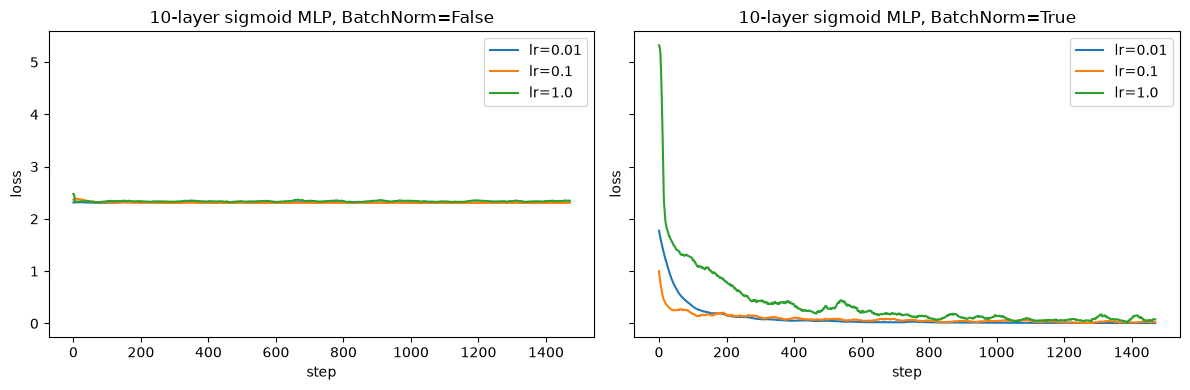

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, bn in zip(axes, [False, True]):
    for lr in [0.01, 0.1, 1.0]: ax.plot(results[(bn, lr)][0], label=f"lr={lr}")
    ax.set(title=f"10-layer sigmoid MLP, BatchNorm={bn}", xlabel="step", ylabel="loss"); ax.legend()
plt.tight_layout(); plt.show()

## Activation statistics per layer
Without BN, sigmoid activations in deep layers drift and saturate (or collapse). With BN, every layer receives inputs with a stable distribution.

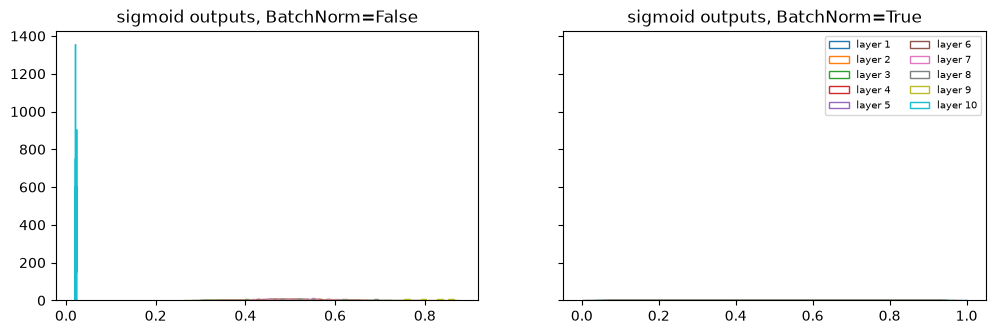

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, bn in zip(axes, [False, True]):
    m = results[(bn, 0.1)][2]; h = Xte; m.eval()
    with torch.no_grad():
        for i, layer in enumerate(m):
            h = layer(h)
            if isinstance(layer, nn.Sigmoid):
                ax.hist(h.flatten().cpu().numpy(), bins=50, histtype="step", density=True, label=f"layer {i // (3 if bn else 2) + 1}")
    ax.set_title(f"sigmoid outputs, BatchNorm={bn}")
axes[1].legend(fontsize=7, ncol=2); plt.show()